# Check prior sensitivity in Meridian without refitting: national model

Fit the model **once**, then reweight the saved posterior draws to see what a *different prior* would give. Pareto k̂ and the ESS tell you when to trust the result.

About 8 minutes on 4 CPU cores, nearly all of it in the fits:
1. Fit the national demo model once (the reference fit).
2. Reweight to a new `roi_m` prior and check against a full refit.
3. Sweep several `roi_m` priors with no refits.
4. Repeat for `alpha_m` (carryover) and `ec_m` (half-saturation).

**How it works.** Each draw gets a weight `new prior density / reference prior density`. If the new prior favours regions where the reference draws are rare, a few draws dominate and the answer is unreliable. Two numbers tell you:

| Pareto k̂ | verdict | meaning |
|---|---|---|
| < 0.5 | **use it** | about as close to a refit as two refits are to each other |
| 0.5 – 0.7 | **check** | probably fine for the mean; refit the priors that drive a decision |
| ≥ 0.7 | **refit** | do not use the reweighted numbers |

The ESS (in % of the draws) is how many draws the weights really use. Below about 10% the reweighted histograms get spiky and the means noisy, even when k̂ is small.

In [1]:
import os, subprocess, sys, time, warnings

try:
    import meridian, arviz
except ImportError:  # e.g. a fresh Colab runtime; restart the runtime if Colab asks for it
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "google-meridian[jax]==2.1.0", "arviz==0.19.0", "matplotlib"], check=True)

os.environ.setdefault("MERIDIAN_BACKEND", "jax")
warnings.filterwarnings("ignore")

import arviz as az
import matplotlib.pyplot as plt
import meridian
import numpy as np
import pandas as pd
import tensorflow_probability.substrates.jax as tfp
from meridian.data import data_frame_input_data_builder
from meridian.model import model, prior_distribution, spec
from scipy import stats
from scipy.special import logsumexp

tfd = tfp.distributions
pd.options.display.float_format = "{:.3f}".format
print("Meridian", meridian.__version__, "| ArviZ", az.__version__)

Meridian 2.1.0 | ArviZ 0.19.0


## 1. Data and reference fit

In [2]:
DATA_URL = ("https://raw.githubusercontent.com/google/meridian/refs/heads/main/"
            "meridian/data/simulated_data/csv/geo_all_channels.csv")
CHANNELS = [f"Channel{i}" for i in range(5)]


def build_national_data():
    """Meridian's 40-geo demo dataset summed over geos to one national series (156 weeks)."""
    df = pd.read_csv(DATA_URL, index_col=0)
    df["time"] = df["time"].astype(str)
    sum_cols = (["conversions", "population", "Organic_channel0_impression"]
                + [f"{c}_impression" for c in CHANNELS] + [f"{c}_spend" for c in CHANNELS])
    mean_cols = ["sentiment_score_control", "competitor_sales_control", "Promo"]   # population-weighted
    rows = []
    for t, g in df.groupby("time", sort=True):
        row = {"time": t, "geo": "national"}
        row.update({c: g[c].sum() for c in sum_cols})
        row.update({c: np.average(g[c], weights=g["population"]) for c in mean_cols})
        row["revenue_per_conversion"] = np.average(g["revenue_per_conversion"], weights=g["conversions"])
        rows.append(row)
    df = pd.DataFrame(rows)
    builder = data_frame_input_data_builder.DataFrameInputDataBuilder(
        kpi_type="non_revenue", default_kpi_column="conversions",
        default_revenue_per_kpi_column="revenue_per_conversion")
    return (builder.with_kpi(df).with_revenue_per_kpi(df).with_population(df)
            .with_controls(df, control_cols=["sentiment_score_control", "competitor_sales_control"])
            .with_media(df, media_cols=[f"{c}_impression" for c in CHANNELS],
                        media_spend_cols=[f"{c}_spend" for c in CHANNELS], media_channels=CHANNELS)
            .with_non_media_treatments(df, non_media_treatment_cols=["Promo"])
            .with_organic_media(df, organic_media_cols=["Organic_channel0_impression"],
                                organic_media_channels=["Organic_channel0"])
            .build())


input_data = build_national_data()
print("national data:", input_data.kpi.shape[1], "weeks,", len(CHANNELS), "media channels")

national data: 156 weeks, 5 media channels


In [3]:
# Settings. The sampling settings are the ones used for the evidence in this repository.
MCMC = dict(n_chains=4, n_adapt=1000, n_burnin=500, n_keep=1000)
ENABLE_AKS = True        # automatic knot selection for the time effect
RUN_REFITS = True        # False skips the "check against a full refit" fits (saves most of the run time)
SEED = 1

In [4]:
# A prior is a pair: the TFP distribution that Meridian samples with, and the SciPy distribution that
# gives the same density for the weights. Defining both from the same numbers keeps them in sync.
f64 = np.float64

def lognormal(mu, sigma):
    return tfd.LogNormal(f64(mu), f64(sigma)), stats.lognorm(s=sigma, scale=np.exp(mu))

def halfnormal(scale):
    return tfd.HalfNormal(f64(scale)), stats.halfnorm(scale=scale)

def beta(a, b):
    return tfd.Beta(f64(a), f64(b)), stats.beta(a, b)

def truncnormal(loc, scale, low, high):
    return (tfd.TruncatedNormal(f64(loc), f64(scale), f64(low), f64(high)),
            stats.truncnorm((low - loc) / scale, (high - loc) / scale, loc=loc, scale=scale))

# Priors of the reference fit. Everything except roi_m is Meridian's default.
REFERENCE = {
    "roi_m": lognormal(0.2, 0.9),
    "alpha_m": (tfd.Uniform(f64(0), f64(1)), stats.uniform(0, 1)),
    "ec_m": truncnormal(0.8, 0.8, 0.1, 10.0),
    "eta_m": halfnormal(1.0),
}

In [5]:
class HashableDict(dict):
    """Meridian 2.1.0 (JAX) needs hashable sampler kwargs."""
    def __hash__(self):
        return hash(tuple(sorted(self.items())))


def fit(prior_overrides, seed):
    """Fit the model with the reference priors, except those in `prior_overrides` ({name: prior pair})."""
    priors = {k: v[0] for k, v in {**{"roi_m": REFERENCE["roi_m"]}, **prior_overrides}.items()}
    mmm = model.Meridian(
        input_data=input_data,
        model_spec=spec.ModelSpec(prior=prior_distribution.PriorDistribution(**priors),
                                  enable_aks=ENABLE_AKS, media_prior_type="roi"))
    t0 = time.perf_counter()
    mmm.sample_posterior(**MCMC, seed=seed, dual_averaging_kwargs=HashableDict(target_accept_prob=0.95))
    print(f"fit: {time.perf_counter() - t0:.0f} s")
    return mmm


def draws_of(mmm, name):
    """Posterior draws of one parameter, chains merged: shape (draws, channels)."""
    x = mmm.inference_data.posterior[name].values
    return x.reshape(-1, x.shape[-1])

In [6]:
# The one expensive step. In real use this is your normal Meridian fit.
mmm = fit({}, seed=SEED)

fit: 114 s


## 2. Reweighting tools
SciPy densities and ArviZ's Pareto smoothing.

In [7]:
STATUS = [(0.5, "use it"), (0.7, "check"), (np.inf, "refit")]


def log_ratio(draws, new, reference):
    """log(new prior / reference prior) per draw, summed over channels. Priors are SciPy distributions."""
    lp_ref = reference.logpdf(draws)
    if not np.all(np.isfinite(lp_ref)):
        raise ValueError("Some draws are outside the reference prior's support.")
    return (new.logpdf(draws) - lp_ref).sum(axis=1)


def psis(log_ratios, reff=1.0):
    """Pareto-smoothed importance weights and their diagnostics.

    Draws with zero density under the new prior get weight 0 and are left out of the smoothing."""
    n = len(log_ratios)
    ok = np.isfinite(log_ratios)
    log_w = np.full(n, -np.inf)
    smoothed, k_hat = az.psislw(log_ratios[ok].copy(), reff=reff)   # psislw edits its input: pass a copy
    log_w[ok] = smoothed
    w = np.exp(log_w - logsumexp(log_w))                             # normalised, sums to 1
    ess = 1.0 / np.sum(w ** 2)
    k_hat = float(k_hat)
    verdict = next(v for limit, v in STATUS if k_hat < limit) if np.isfinite(k_hat) else "refit"
    return dict(w=w, k_hat=k_hat, ess_pct=100 * ess / n, verdict=verdict)


def relative_efficiency(mmm, names):
    """Share of the draws that are effectively independent (MCMC autocorrelation), as arviz.loo does."""
    post = mmm.inference_data.posterior
    n = post.sizes["chain"] * post.sizes["draw"]
    ess = np.concatenate([az.ess(post[[v]], method="mean")[v].values.ravel() for v in names])
    return float(min(ess.mean() / n, 1.0))


def weighted_mean(x, w):
    return (w[:, None] * x).sum(axis=0)


def weighted_quantile(x, w, q):
    out = []
    for j in range(x.shape[1]):
        order = np.argsort(x[:, j])
        cdf = np.cumsum(w[order]) - 0.5 * w[order]
        out.append(np.interp(q, cdf, x[order, j]))
    return np.array(out)


def check_reference_priors(mmm, names):
    """The weights are only right if REFERENCE matches the priors Meridian really used."""
    for name in names:
        x = draws_of(mmm, name)
        meridian_lp = np.asarray(getattr(mmm.prior_broadcast, name).log_prob(x))
        assert np.allclose(meridian_lp, REFERENCE[name][1].logpdf(x), rtol=1e-6), f"reference prior mismatch: {name}"
    print("Reference priors match what Meridian used:", ", ".join(names))

In [8]:
def plot_posteriors(param, draws, w, refit_draws=None, ref_label="reference fit"):
    """Per channel: reference posterior, reweighted posterior and (optionally) the full refit."""
    k = draws.shape[1]
    lo, hi = np.quantile(draws, 0.001, axis=0), np.quantile(draws, 0.999, axis=0)
    if refit_draws is not None:
        lo, hi = np.minimum(lo, refit_draws.min(0)), np.maximum(hi, np.quantile(refit_draws, 0.999, axis=0))
    fig, axes = plt.subplots(1, k, figsize=(3.0 * k, 2.6), sharey=False)
    for j, ax in enumerate(np.atleast_1d(axes)):
        bins = np.linspace(lo[j], hi[j], 50)
        mid = 0.5 * (bins[1:] + bins[:-1])
        ax.step(mid, np.histogram(draws[:, j], bins, density=True)[0], color="0.6", label=ref_label)
        ax.step(mid, np.histogram(draws[:, j], bins, weights=w, density=True)[0], color="C0", lw=2, label="reweighted")
        if refit_draws is not None:
            ax.step(mid, np.histogram(refit_draws[:, j], bins, density=True)[0], color="C1", ls="--", lw=2,
                    label="full refit")
        ax.set_title(f"{param}, channel {j}", fontsize=10)
        ax.set_yticks([])
    np.atleast_1d(axes)[0].legend(fontsize=8, frameon=False)
    plt.tight_layout()
    plt.show()


def summary_table(param, draws, w, refit_draws=None):
    """Posterior mean per channel: reference, reweighted and (optionally) refit."""
    t = pd.DataFrame({"reference": draws.mean(0), "reweighted": weighted_mean(draws, w)})
    if refit_draws is not None:
        t["full refit"] = refit_draws.mean(0)
        t["|reweighted - refit|"] = (t["reweighted"] - t["full refit"]).abs()
        t["... in refit SDs"] = t["|reweighted - refit|"] / refit_draws.std(axis=0, ddof=1)
    t.index.name = f"{param} mean, channel"
    return t

In [9]:
def try_prior(param, new, mmm_ref, seed, refit=None):
    """Reweight the reference draws to a new prior on `param`; optionally refit to check the answer.

    new: prior pair, e.g. lognormal(0.5, 0.6). refit: True/False (default RUN_REFITS)."""
    refit = RUN_REFITS if refit is None else refit
    x = draws_of(mmm_ref, param)
    t0 = time.perf_counter()
    r = psis(log_ratio(x, new[1], REFERENCE[param][1]), reff)
    print(f"reweighting took {time.perf_counter() - t0:.3f} s")
    print(f"k-hat = {r['k_hat']:.2f}, ESS = {r['ess_pct']:.0f}% of the draws  ->  {r['verdict'].upper()}")
    refit_x = draws_of(fit({param: new}, seed), param) if refit else None
    plot_posteriors(param, x, r["w"], refit_x)
    display(summary_table(param, x, r["w"], refit_x))
    return r

In [10]:
check_reference_priors(mmm, ["roi_m", "alpha_m", "ec_m"])
reff = relative_efficiency(mmm, ["roi_m", "alpha_m", "ec_m"])
print(f"relative MCMC efficiency of the reference fit: {reff:.2f}")

Reference priors match what Meridian used: roi_m, alpha_m, ec_m
relative MCMC efficiency of the reference fit: 0.94


## 3. One new prior, checked against a full refit
A higher, tighter ROI prior: `LogNormal(0.5, 0.6)` instead of `LogNormal(0.2, 0.9)`. The reweighting takes milliseconds. The refit (dashed orange) is only here to check it. Refits with different seeds differ a little too, so compare `|reweighted - refit|` with that noise, not with zero. The last column is the error in refit posterior SDs; its median in the 300-prior national test was 0.03 to 0.1 up to mid distance (see `evidence/`).

reweighting took 0.004 s
k-hat = 0.41, ESS = 6% of the draws  ->  USE IT


fit: 103 s


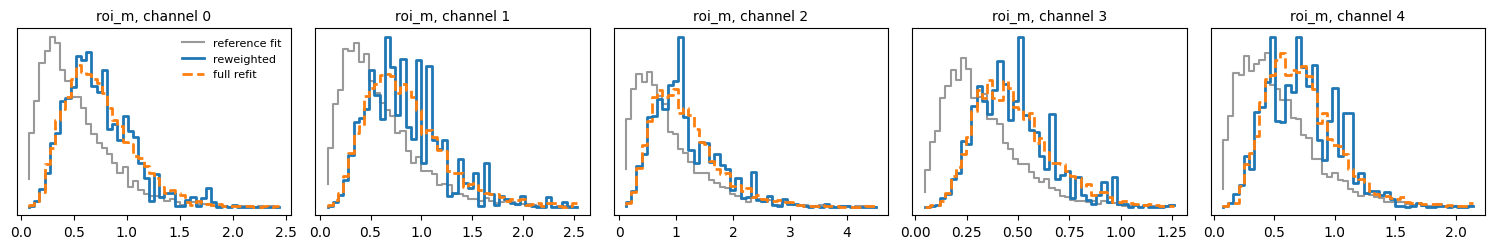

,reference,reweighted,full refit,|reweighted - refit|,... in refit SDs
"roi_m mean, channel",,,,,
0,0.532,0.753,0.760,0.007,0.023
1,0.608,0.869,0.867,0.002,0.004
2,0.889,1.210,1.196,0.015,0.025
3,0.335,0.489,0.495,0.006,0.033
4,0.542,0.753,0.747,0.006,0.020


In [11]:
r_roi = try_prior("roi_m", lognormal(0.5, 0.6), mmm, seed=SEED + 1)

## 4. A sensitivity sweep with no refits
The real use case: several candidate priors, one table. **refit** rows are priors the reference draws cannot answer; run a real fit for them. Their means are left out on purpose.

In [12]:
roi_draws = draws_of(mmm, "roi_m")
candidates = {
    "LogNormal(0.2, 0.6)  same median, tighter": lognormal(0.2, 0.6),
    "LogNormal(0.2, 1.2)  same median, wider": lognormal(0.2, 1.2),
    "LogNormal(0.0, 0.9)  lower": lognormal(0.0, 0.9),
    "LogNormal(0.4, 0.9)  higher": lognormal(0.4, 0.9),
    "LogNormal(0.6, 0.6)  higher, tight": lognormal(0.6, 0.6),
    "LogNormal(0.8, 0.5)  far": lognormal(0.8, 0.5),
    "LogNormal(1.2, 0.45) very far": lognormal(1.2, 0.45),
}
rows = []
for label, prior in candidates.items():
    r = psis(log_ratio(roi_draws, prior[1], REFERENCE["roi_m"][1]), reff)
    means = weighted_mean(roi_draws, r["w"]) if r["verdict"] != "refit" else np.full(roi_draws.shape[1], np.nan)
    rows.append({"new roi_m prior": label, "k-hat": r["k_hat"], "ESS %": r["ess_pct"], "verdict": r["verdict"],
                 **{f"ROI ch{j}": m for j, m in enumerate(means)}})
reference_row = {"new roi_m prior": "reference fit", "k-hat": np.nan, "ESS %": 100.0, "verdict": "-",
                 **{f"ROI ch{j}": m for j, m in enumerate(roi_draws.mean(0))}}
pd.DataFrame([reference_row] + rows).set_index("new roi_m prior")

,k-hat,ESS %,verdict,ROI ch0,ROI ch1,ROI ch2,ROI ch3,ROI ch4
new roi_m prior,,,,,,,,
reference fit,NaN,100.000,-,0.532,0.608,0.889,0.335,0.542
"LogNormal(0.2, 0.6) same median, tighter",0.043,20.695,use it,0.679,0.752,1.018,0.461,0.685
"LogNormal(0.2, 1.2) same median, wider",0.446,24.124,use it,0.445,0.518,0.767,0.261,0.472
"LogNormal(0.0, 0.9) lower",0.076,89.636,use it,0.496,0.563,0.798,0.317,0.509
"LogNormal(0.4, 0.9) higher",-0.253,90.754,use it,0.569,0.655,0.983,0.354,0.576
"LogNormal(0.6, 0.6) higher, tight",0.545,4.070,check,0.770,0.906,1.280,0.497,0.769
"LogNormal(0.8, 0.5) far",1.430,0.477,refit,NaN,NaN,NaN,NaN,NaN
"LogNormal(1.2, 0.45) very far",2.846,0.240,refit,NaN,NaN,NaN,NaN,NaN


## 5. Other parameters
Same recipe: swap the two densities. Each cell reweights, then refits once to confirm.

reweighting took 0.004 s
k-hat = -0.30, ESS = 42% of the draws  ->  USE IT


fit: 101 s


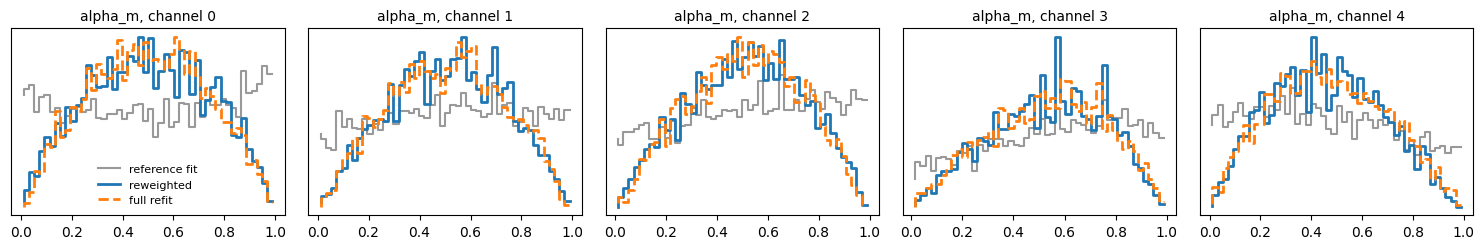

,reference,reweighted,full refit,|reweighted - refit|,... in refit SDs
"alpha_m mean, channel",,,,,
0,0.510,0.509,0.510,0.001,0.005
1,0.521,0.518,0.515,0.004,0.018
2,0.536,0.521,0.520,0.001,0.005
3,0.561,0.542,0.541,0.002,0.008
4,0.461,0.471,0.478,0.007,0.033


In [13]:
r_alpha = try_prior("alpha_m", beta(2.0, 2.0), mmm, seed=SEED + 2)

reweighting took 0.006 s
k-hat = 0.17, ESS = 82% of the draws  ->  USE IT


fit: 103 s


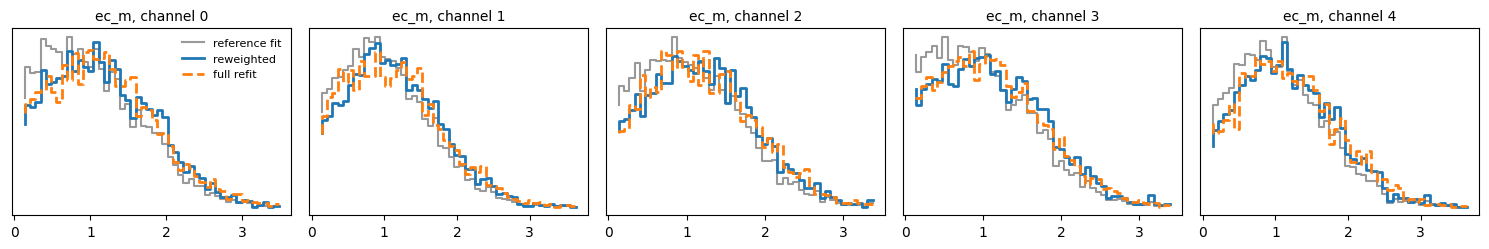

,reference,reweighted,full refit,|reweighted - refit|,... in refit SDs
"ec_m mean, channel",,,,,
0,1.072,1.202,1.205,0.003,0.004
1,1.056,1.168,1.166,0.003,0.004
2,1.101,1.233,1.231,0.002,0.003
3,1.030,1.158,1.146,0.012,0.019
4,1.096,1.212,1.230,0.018,0.028


In [14]:
r_ec = try_prior("ec_m", truncnormal(1.0, 0.8, 0.1, 10.0), mmm, seed=SEED + 3)

### Two parameters at once
Add the log ratios, then smooth once. Changes that are fine alone can fail together, so check the joint k̂.

In [15]:
x_a, x_e = draws_of(mmm, "alpha_m"), draws_of(mmm, "ec_m")
lr_a = log_ratio(x_a, beta(2.0, 2.0)[1], REFERENCE["alpha_m"][1])
lr_e = log_ratio(x_e, truncnormal(1.0, 0.8, 0.1, 10.0)[1], REFERENCE["ec_m"][1])
for label, lr in [("alpha_m only", lr_a), ("ec_m only", lr_e), ("both", lr_a + lr_e)]:
    r = psis(lr, reff)
    print(f"{label:13s} k-hat = {r['k_hat']:5.2f}   ESS = {r['ess_pct']:3.0f}%   {r['verdict']}")

alpha_m only  k-hat = -0.30   ESS =  42%   use it
ec_m only     k-hat =  0.17   ESS =  82%   use it
both          k-hat =  0.11   ESS =  35%   use it


## Limits
- **Only the prior changes.** Same data, model structure and likelihood. A different `media_prior_type`, new controls or a new likelihood need a refit.
- **Support.** The new prior must put its mass where the reference prior does; draws with zero density under the new prior get weight 0.
- **Point-mass priors cannot be reweighted**, e.g. Meridian's default `slope_m = Deterministic(1.0)`.
- **Tested on Meridian 2.1.0 (JAX)** with the demo data. The evidence behind the k̂ thresholds is in `evidence/`.